# 4. Model Training
Kai models ko ek hi pipeline (scaling + one-hot encoding) ke saath compare karna.

**Input:** `data/processed/03_features.csv`  
**Output:** `data/artifacts/baseline/baseline_pipeline.joblib`, `data/artifacts/baseline/baseline_results.csv`

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_val_score

from common import (
    BASELINE_PIPELINE_FILE, BASELINE_RESULTS_FILE, RANDOM_STATE,
    load_features, split_data, get_cv, make_pipeline, evaluate,
)

In [2]:
df = load_features()
X_train, X_test, y_train, y_test = split_data(df)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1018, 12) | Test: (255, 12)


In [3]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE),
}

In [4]:
rows, fitted = [], {}

for name, model in models.items():
    pipe = make_pipeline(model)

    # 5-fold CV on the training data only (model selection)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=get_cv(), scoring="r2").mean()

    # Fit on the full training set and score once on the untouched test set
    pipe.fit(X_train, y_train)
    metrics = evaluate(pipe, X_test, y_test)

    fitted[name] = pipe
    rows.append({"model": name, "cv_r2_log": cv_r2, **{f"test_{k}": v for k, v in metrics.items()}})
    print(f"{name:<18} CV R2 = {cv_r2:.3f} | test R2 = {metrics['r2_log']:.3f}")

results = pd.DataFrame(rows).sort_values("cv_r2_log", ascending=False).reset_index(drop=True)
results.round(3)

Linear Regression  CV R2 = 0.616 | test R2 = 0.668
Ridge              CV R2 = 0.616 | test R2 = 0.668


Lasso              CV R2 = 0.616 | test R2 = 0.667


KNN                CV R2 = 0.802 | test R2 = 0.803
Decision Tree      CV R2 = 0.793 | test R2 = 0.810


Random Forest      CV R2 = 0.864 | test R2 = 0.880


Extra Trees        CV R2 = 0.861 | test R2 = 0.867


Gradient Boosting  CV R2 = 0.879 | test R2 = 0.870


,model,cv_r2_log,test_r2_log,test_r2_price,test_mae_price
0,Gradient Boosting,0.879,0.870,0.815,10925.159
1,Random Forest,0.864,0.880,0.821,10359.640
2,Extra Trees,0.861,0.867,0.804,11030.991
3,KNN,0.802,0.803,0.718,12920.874
4,Decision Tree,0.793,0.810,0.722,12540.274
5,Lasso,0.616,0.667,0.522,17306.767
6,Ridge,0.616,0.668,0.516,17349.636
7,Linear Regression,0.616,0.668,0.516,17352.079


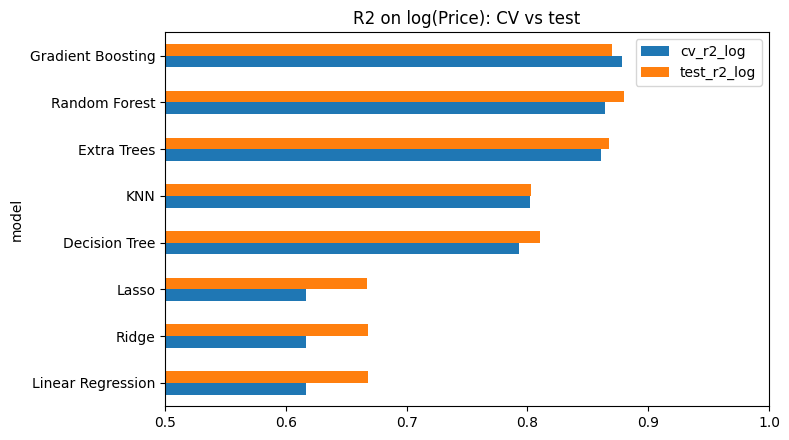

In [5]:
ax = results.set_index("model")[["cv_r2_log", "test_r2_log"]].sort_values("cv_r2_log").plot(
    kind="barh", figsize=(8, 4.5), title="R2 on log(Price): CV vs test"
)
ax.set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

In [6]:
# Best model by CV score (not by test score, to keep the test set honest)
best_name = results.loc[0, "model"]
print("Best baseline:", best_name)

joblib.dump(fitted[best_name], BASELINE_PIPELINE_FILE)
results.to_csv(BASELINE_RESULTS_FILE, index=False)
print("Saved:", BASELINE_PIPELINE_FILE.name, "and", BASELINE_RESULTS_FILE.name)

Best baseline: Gradient Boosting
Saved: baseline_pipeline.joblib and baseline_results.csv
